In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

## Part 1

The NeoWs csv can be created using one of two files. The first, ```/src/read_data_from_api.ipynb```, requests the data from the api and structures it approapriately for analysis. This file can be execute from the ```/src``` directory using ```python3 read_data_from_api.py```. The second, ```/notebook/load_data.ipynb```, performs the same opperations as ```read_data_from_api.ipynb``` but shows the structure of the raw data from the API.

In [2]:
csv_fpath = os.path.join("..", "data", "raw", "neo_data.csv")

neos_df = pd.read_csv(csv_fpath, dtype={
    "Approach Date": str,
    "miss_distance": float,
    "relative_velocity": float,
    "object_id": str,
    "absolute_magnitude_h": float,
    "estimated_diameter": float,
    "is_potentially_hazardous_asteroid": bool
    }, parse_dates=["Approach Date"])

## Part 2

In [3]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

import neo_functions as nf

In [4]:
hazardous_neos = nf.group_neos_by_hazardous_flag(df=neos_df, hazardous_flag=True)
nonhazardous_neos = nf.group_neos_by_hazardous_flag(df=neos_df, hazardous_flag=False)

In [5]:
display(hazardous_neos.head())
display(nonhazardous_neos.head())

,Approach Date,miss_distance,relative_velocity,object_id,absolute_magnitude_h,estimated_diameter,is_potentially_hazardous_asteroid
18,2026-10-28,5.848717e+07,52895.829085,2518810,21.85,0.113385,True
19,2026-10-28,4.240878e+06,33549.810808,2518810,21.85,0.113385,True
20,2026-10-28,2.289518e+07,20345.824816,2518810,21.85,0.113385,True
21,2026-10-28,3.383045e+07,52334.090119,2518810,21.85,0.113385,True
22,2026-10-28,6.556904e+07,40395.479196,2518810,21.85,0.113385,True


,Approach Date,miss_distance,relative_velocity,object_id,absolute_magnitude_h,estimated_diameter,is_potentially_hazardous_asteroid
0,2026-10-26,6.642528e+07,67073.229700,2488509,20.61,0.200704,False
1,2026-10-26,4.635502e+07,32270.110647,2488509,20.61,0.200704,False
2,2026-10-26,4.509338e+07,73474.264537,2488509,20.61,0.200704,False
3,2026-10-26,2.116466e+07,12565.295839,2488509,20.61,0.200704,False
4,2026-10-26,6.486772e+07,71372.128055,2488509,20.61,0.200704,False


In [6]:
filtered_hazardous_neos = nf.filter_by_date(df=hazardous_neos, start_date="2026-10-21", end_date="2026-10-22")
display(filtered_hazardous_neos.head())

,Approach Date,miss_distance,relative_velocity,object_id,absolute_magnitude_h,estimated_diameter,is_potentially_hazardous_asteroid
93,2026-10-21,5.556045e+07,28776.250761,3387458,21.88,0.111829,True
94,2026-10-21,5.737689e+07,67295.922468,3387458,21.88,0.111829,True
95,2026-10-21,3.029499e+07,50814.451712,3387458,21.88,0.111829,True
96,2026-10-21,3.387593e+07,27858.622741,3387458,21.88,0.111829,True
97,2026-10-21,4.628238e+07,46586.495612,3387458,21.88,0.111829,True


In [7]:
hazardous_neos_summary, nonhazardous_neos_summary = nf.summarize_potentialy_hazardous_neos(df=neos_df)
display(hazardous_neos_summary.head())
display(nonhazardous_neos_summary.head())

,n_approaches,miss_min,miss_median,miss_max,vel_min,vel_median,vel_max,absolute_magnitude_h,estimated_diameter,hazardous
object_id,,,,,,,,,,
2518810,6,4240878.05,40771124.53,65569040.72,20345.82,45495.14,52895.83,21.85,0.11,True
3387458,10,30294985.22,46741360.34,59698211.11,27858.62,58049.68,132950.77,21.88,0.11,True
3753695,10,30294985.22,46741360.34,59698211.11,27858.62,58049.68,132950.77,19.88,0.28,True
3757572,6,4240878.05,40771124.53,65569040.72,20345.82,45495.14,52895.83,20.91,0.17,True
3831888,9,12978705.60,45093384.61,66425278.81,12565.30,67073.23,83219.21,19.91,0.28,True


,n_approaches,miss_min,miss_median,miss_max,vel_min,vel_median,vel_max,absolute_magnitude_h,estimated_diameter,hazardous
object_id,,,,,,,,,,
2488509,9,12978705.60,45093384.61,66425278.81,12565.30,67073.23,83219.21,20.61,0.20,False
2516803,9,12978705.60,45093384.61,66425278.81,12565.30,67073.23,83219.21,19.52,0.33,False
2529819,8,13765534.89,45154508.84,74781124.91,30420.51,44745.75,74413.76,20.86,0.18,False
3092205,10,10212926.31,39574452.97,60313373.13,25575.96,51312.87,128914.27,19.49,0.34,False
3114023,8,13765534.89,45154508.84,74781124.91,30420.51,44745.75,74413.76,26.10,0.02,False


## Part 3

Question 1)

Compare hazardous and non-hazardous NEOs. How many more hazardous and non-hazardas object are there? How many hazardous and non-hazardas observations are there? Compare diameters and miss distances.

In [8]:
n_hazardous = len(hazardous_neos_summary)
n_nonhazardous = len(nonhazardous_neos_summary)
print(f"There are {n_hazardous} hazardous objects and {n_nonhazardous} non-hazardous objects.")

There are 5 hazardous objects and 55 non-hazardous objects.


In [9]:
n_hazardous = hazardous_neos_summary['n_approaches'].sum()
n_nonhazardous = nonhazardous_neos_summary['n_approaches'].sum()
print(f"There are {n_hazardous} hazardous observations and {n_nonhazardous} non-hazardous observations.")

There are 41 hazardous observations and 439 non-hazardous observations.


In [10]:
mean_hazardous_neos_diameter = hazardous_neos_summary['estimated_diameter'].mean()
mean_nonhazardous_neos_diameter = nonhazardous_neos_summary['estimated_diameter'].mean()

print(f"Mean estimated diameter for hazardous NEOs: {mean_hazardous_neos_diameter:.2f} km")
print(f"Mean estimated diameter for non-hazardous NEOs: {mean_nonhazardous_neos_diameter:.2f} km")

Mean estimated diameter for hazardous NEOs: 0.19 km
Mean estimated diameter for non-hazardous NEOs: 0.07 km


In [11]:
median_hazardous_neos_miss = hazardous_neos_summary['miss_median'].mean()
median_nonhazardous_neos_miss = nonhazardous_neos_summary['miss_median'].mean()

print(f"Median miss distance (km) for hazardous NEOs: {median_hazardous_neos_miss:.2f} km")
print(f"Median miss distance (km) for non-hazardous NEOs: {median_nonhazardous_neos_miss:.2f} km")

Median miss distance (km) for hazardous NEOs: 44023670.87 km
Median miss distance (km) for non-hazardous NEOs: 41372759.99 km


Question 1)

Compare hazardous and non-hazardous NEOs. How many more hazardous and non-hazardas object are there? How many hazardous and non-hazardas observations are there? Compare diameters and miss distances.

Answer 1)

There are far more non-hazardous objects and observations than hazardous objects. There are 41 hazardous observations and 5 hazardous objects copmared to 439 non-hazardous observations and 55 non-hazardous objects. Hazardous NEOs appear to be larger but further to Earth than non-hazardou NEOs. The mean estimated diameter for hazardous NEOs is 0.19 km and is a median 44,023,670.87 km from Earth. In comparison, the mean estimated diameter for non-hazardous NEOs is 0.07 km and is a median 41,372,759.99 km from Earth.

Question 2)

Examine the diameters and miss distances for all objects and compare to the grouped results.

In [12]:
n_objects = len(neos_df.groupby('object_id'))
print(f"There are {n_objects} objects total.")

There are 60 objects total.


In [13]:
n_observations = len(neos_df)
print(f"There are {n_observations} observations total.")

There are 480 observations total.


In [14]:
mean_neos_diameter = neos_df.groupby('object_id')['estimated_diameter'].first().mean().item()
print(f"Mean estimated diameter for all NEOs: {mean_neos_diameter:.2f} km")

Mean estimated diameter for all NEOs: 0.08 km


In [15]:
median_neos_miss = neos_df.groupby('object_id')['miss_distance'].first().median().item()
print(f"Median miss distance (km) for all NEOs: {median_neos_miss:.2f} km")

Median miss distance (km) for all NEOs: 45154508.84 km


Question 2)

Examine the diameters and miss distances for all objects and compare to the grouped results.

Answer 2)

 The mean diameter for all NEOs is about 0.08 km, this is closer to the mean diameter of the non-hazardous objects. The median miss distance for all NEOs is 45,154,508.84 km which is closer to the median of the hazardous NEOs. The mean diameter of all objects is closer to the mean diameter of the non-hazardous NEOs because the dataset is very unbalanced with 55 out of 60 objects are non-hazardous.

## Part 4

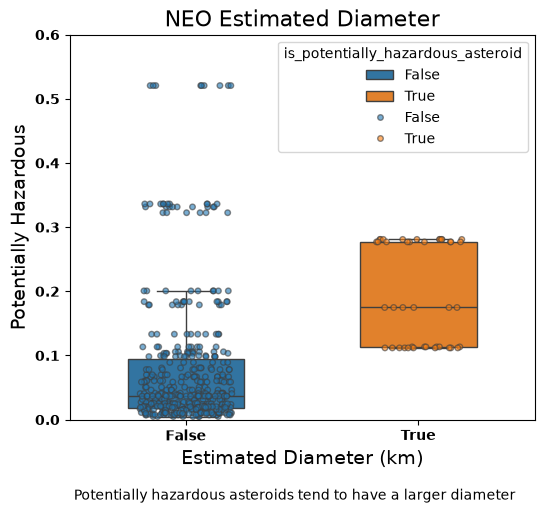

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.boxplot(data=neos_df, x='is_potentially_hazardous_asteroid', y='estimated_diameter', ax=ax,
            hue='is_potentially_hazardous_asteroid', showfliers=False, width=0.5)

sns.stripplot(data=neos_df, x='is_potentially_hazardous_asteroid', y='estimated_diameter', ax=ax,
              jitter=0.2, size=4, alpha=0.6, hue='is_potentially_hazardous_asteroid', linewidth=1)

ax.set_title("NEO Estimated Diameter", fontsize=16)
ax.set_xlabel("Estimated Diameter (km)", fontsize=14)
ax.set_ylabel("Potentially Hazardous", fontsize=14)
ax.set_ylim(0, 0.6)

for label in ax.get_xticklabels():
    label.set_weight('bold')
for label in ax.get_yticklabels():
    label.set_weight('bold')

fig.text(0.5, -0.05, "Potentially hazardous asteroids tend to have a larger diameter", wrap=True, horizontalalignment='center', fontsize=10)

fig_path = os.path.join("..", "figures", "NEO_diameter_by_hazardness.png")
fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

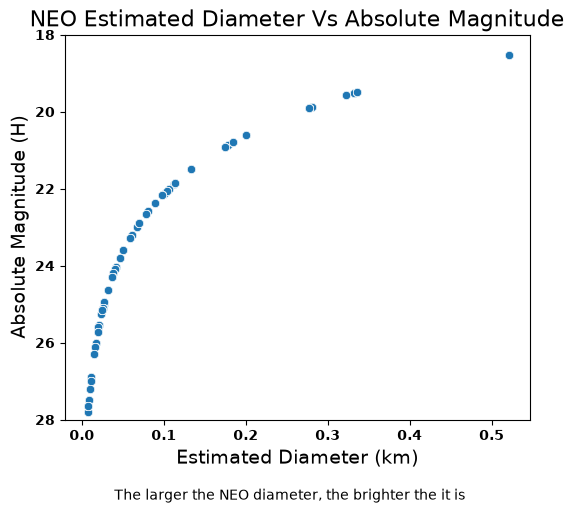

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.scatterplot(data=neos_df, x='estimated_diameter', y='absolute_magnitude_h', ax=ax)

ax.set_title("NEO Estimated Diameter Vs Absolute Magnitude", fontsize=16)
ax.set_xlabel("Estimated Diameter (km)", fontsize=14)
ax.set_ylabel("Absolute Magnitude (H)", fontsize=14)
ax.set_ylim(28, 18)
ax.set_yinverted(True)

for label in ax.get_xticklabels():
    label.set_weight('bold')
for label in ax.get_yticklabels():
    label.set_weight('bold')

fig.text(0.5, -0.05, "The larger the NEO diameter, the brighter the it is", wrap=True, horizontalalignment='center', fontsize=10)

fig_path = os.path.join("..", "figures", "NEO_diameter_vs_H.png")
fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

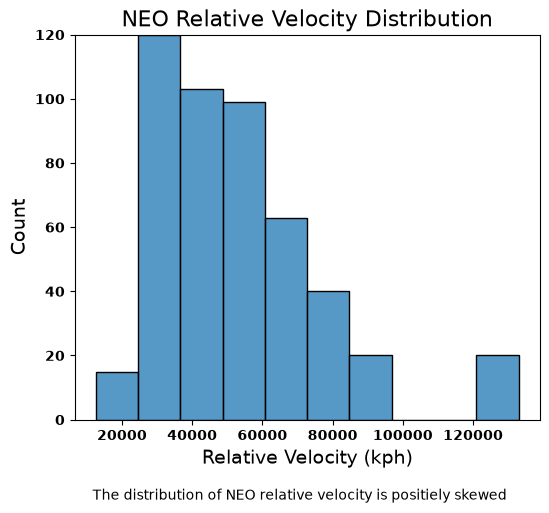

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.histplot(data=neos_df, x='relative_velocity', ax=ax, bins=10)

ax.set_title("NEO Relative Velocity Distribution", fontsize=16)
ax.set_xlabel("Relative Velocity (kph)", fontsize=14)
ax.set_ylabel("Count", fontsize=14)
ax.set_ylim(0, 120)

for label in ax.get_xticklabels():
    label.set_weight('bold')
for label in ax.get_yticklabels():
    label.set_weight('bold')

fig.text(0.5, -0.05, "The distribution of NEO relative velocity is positiely skewed", wrap=True, horizontalalignment='center', fontsize=10)

fig_path = os.path.join("..", "figures", "NEO_relative_velocity_hist.png")
fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()